<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">NBA Opening &amp; Closing Odds — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">The figures of the listing and of its README, recomputed from the file of the
full product: 10,323 NBA games from October 2018 to 1 November 2026, opening and closing prices from 9 US books,
Pinnacle, Bet365, Kalshi and Polymarket, each with the time it was recorded.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing or of the
README, recomputes it from the file and prints **PASS** or **FAIL**. The expected values are written once, in plain
sight, in the `CLAIMS` cell; everything else is read from the data. Only the counts of prices removed while the
file was built (2,172 lagging closes and the others listed in the README) cannot be recomputed: those prices are,
by definition, not in the file.

🏀 **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/degjxu?utm_source=github&utm_medium=notebook&utm_campaign=nba_oc&utm_content=notebook_top)** · also on [Whop](https://whop.com/oliviersportsdata/nba-opening-closing-odds-9-us-books-pinnacle-2018-2026/?utm_source=github&utm_medium=notebook&utm_campaign=nba_oc&utm_content=whop_top) · free 20-game sample: same layout, same 284 columns.

## 0 · Setup

In [1]:
import os, glob, math, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

def find_csv():
    """The CSV of the full product: the largest NBA_Opening_Closing_Odds file wins (sample and full may both be attached)."""
    hits = []
    for base in (os.environ.get("NBA_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += [p for p in glob.glob(os.path.join(base, "**", "NBA_Opening_Closing_Odds_2018-2026*.csv"), recursive=True)
                     if os.path.isfile(p)]
    if not hits:
        raise FileNotFoundError("NBA_Opening_Closing_Odds_2018-2026.csv not found: attach the dataset to this notebook")
    return max(hits, key=os.path.getsize)

PATH = find_csv()
RAW = pd.read_csv(PATH, dtype=str)                 # every cell exactly as written in the file
F = pd.read_csv(PATH, low_memory=False)            # the same file, numbers parsed
print(f"{os.path.basename(PATH)}  ·  {os.path.getsize(PATH) / 1e6:.1f} MB  ·  {len(F):,} rows  ·  {F.shape[1]} columns")

SOURCES = ["Pinnacle", "Bet365", "FanDuel", "DraftKings", "BetMGM", "Caesars", "BetRivers", "BetOnline",
           "theScore", "Fanatics", "HardRock", "Kalshi", "Polymarket"]
BOOKS = SOURCES[:11]                               # the sportsbooks; Kalshi and Polymarket are prediction markets
US = ["FanDuel", "DraftKings", "BetMGM", "Caesars", "BetRivers", "BetOnline", "theScore", "Fanatics", "HardRock"]
NAME = {"HardRock": "Hard Rock"}
ODDS = list(F.columns[14:])
PRICES = [c for c in ODDS if not c.endswith("_Time") and "_Line_" not in c]
KICK = pd.to_datetime(F["Kickoff_UTC"], utc=True)
RESTART = pd.Timestamp("2020-07-01", tz="UTC")     # the NBA restarted in the Orlando bubble on 30 July 2020

def ts(col):
    return pd.to_datetime(F[col], utc=True)

def minutes_vs_tipoff(col):
    """Minutes between the recorded time and the scheduled tip-off: negative = before."""
    return (ts(col) - KICK).dt.total_seconds() / 60

def no_vig(home, away):
    """Implied probability of the home team from two American prices, margin removed proportionally."""
    def imp(us):
        us = np.asarray(us, float)
        with np.errstate(divide="ignore", invalid="ignore"):
            return np.where(us < 0, -us / (100 - us), 100 / (us + 100))
    h, a = imp(home), imp(away)
    return h / (h + a)

RESULTS = []
def check(claim, ok, detail=""):
    ok = bool(ok)
    RESULTS.append((claim, ok, detail))
    print(f"{'PASS' if ok else 'FAIL'}  {claim}" + (f"   [{detail}]" if detail else ""))

# Olivier Sports Data dark signature
BG, FG, FG2, GRID, CYAN, AMBER = "#080c10", "#e6edf3", "#9aa7b2", "#1c2630", "#00d4ff", "#e3a008"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": FG,
                     "axes.labelcolor": FG, "axes.edgecolor": GRID, "xtick.color": FG2, "ytick.color": FG2,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.titlecolor": FG,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10, "legend.frameon": False})

NBA_Opening_Closing_Odds_2018-2026.csv  ·  17.8 MB  ·  10,323 rows  ·  284 columns


## 1 · The claims

Copied from the listing and the README shipped in the ZIP. Nothing below is adjusted to fit: if the file
disagrees, the cell prints FAIL.

In [2]:
CLAIMS = {
    "games": 10_323, "columns": 284, "sources": 13, "prices": 882_226, "overtime": 541,
    "first_game": "20181016_PHI_BOS", "last_game_date": "20261101", "games_2026_27": 92,
    "games_per_season": {"2018/2019": 1_312, "2019/2020": 1_143, "2020/2021": 1_171, "2021/2022": 1_323,
                         "2022/2023": 1_320, "2023/2024": 1_319, "2024/2025": 1_321, "2025/2026": 1_322,
                         "2026/2027": 92},
    "per_stage": {"Regular Season": 9_611, "Play-In": 37, "Playoffs": 672, "NBA Cup Final": 3},
    "columns_per_source": {"Pinnacle": 38, "Kalshi": 6, "Polymarket": 6, "other books": 22},
    # first game with a price, source by source (listing table: closing / opening)
    "first_close": {"Pinnacle": "2018-10", "Bet365": "2018-10", "FanDuel": "2018-11", "DraftKings": "2019-01",
                    "BetRivers": "2019-10", "Caesars": "2020-02", "BetOnline": "2020-07", "BetMGM": "2020-08",
                    "theScore": "2023-11", "HardRock": "2025-03", "Fanatics": "2025-10", "Kalshi": "2025-12",
                    "Polymarket": "2026-01"},
    "first_open": {"Pinnacle": "2018-10", "Bet365": "2018-10", "FanDuel": "2020-07", "DraftKings": "2020-07",
                   "BetRivers": "2026-10", "Caesars": "2020-07", "BetOnline": "2020-07", "BetMGM": "2020-12",
                   "theScore": "2023-11", "HardRock": "2026-10", "Fanatics": "2026-10", "Kalshi": "2026-10",
                   "Polymarket": "2026-10"},
    "first_close_day": {"FanDuel": "20181108", "DraftKings": "20190130", "HardRock": "20250314", "Fanatics": "20251021"},
    # README: median closing moneyline vs scheduled tip-off, minutes (Pinnacle from the July 2020 restart)
    "median_close_min": {"Pinnacle": 9, "Bet365": -2, "BetRivers": -16, "FanDuel": 1, "DraftKings": 1, "BetMGM": 1,
                         "Caesars": 1, "BetOnline": 1, "theScore": 1, "Fanatics": 1, "HardRock": 1, "Kalshi": 1,
                         "Polymarket": 1},
    "oldest_close_hours": 12, "latest_close_minutes": 30, "open_without_close": 1_182,
    "bet365_early_close_2026_27": 78,
    "team_totals_games": 7_673, "team_totals_both_closing": 7_381,
    "team_totals_first": "20201231", "team_totals_last": "20260613_NYK_SAS",
    "team_totals_2025_26_closing": {"Home": 83, "Away": 86},
    "kalshi_polymarket_same_close_2026_27": 63,
    "corrected_score": ("20251107_CLE_WAS", 148, 115),
    # listing: median age of the closing moneyline at the scheduled tip-off, before the March 2020 pause and in the bubble
    "median_age_minutes": {("FanDuel", "2018-19"): 19, ("Caesars", "2019-20 before the pause"): 50,
                           ("DraftKings", "2019-20 before the pause"): 70, ("BetRivers", "2019-20 before the pause"): 72,
                           ("BetMGM", "2020 bubble"): 92},
    "median_age_hours": {("FanDuel", "2019-20 before the pause"): 5, ("Pinnacle", "2018-19"): 5.4,
                         ("Pinnacle", "2019-20 before the pause"): 5.1},
    # the games drawn on the listing's images
    "same_second_game": ("20261101_BOS_ORL", 13, 29),                 # sources, seconds before tip-off
    "spread_move_game": ("20261028_LAL_LAC", 5.5, 9, 10, 11),         # opening line, books at it, closed favourite, books
    "finals_game": ("20260613_NYK_SAS", (94, 90), (110.5, 105.5)),    # away-home score, home-away team totals at the close
    # NBA Finals since the July 2020 restart (stated with the free sample)
    "finals": {"games": 40, "with_us_opening": 3, "bet365_opening": 40, "pinnacle_opening": 34,
               "other_playoff_games": 550, "other_with_us_opening": 530},
}
# README coverage tables: share of games with a closing / opening moneyline, % rounded down, "–" = 0
def table(text):
    rows = [r.split() for r in text.strip().splitlines()]
    return {r[0]: {s: (0 if v == "–" else int(v)) for s, v in zip(SOURCES, r[1:])} for r in rows}
CLAIMS["close_cov"] = table("""
2018/2019 95 99 86 41 – – – – – – – – –
2019/2020 92 99 85 91 12 28 89 13 – – – – –
2020/2021 99 99 100 99 91 99 97 97 – – – – –
2021/2022 99 99 99 99 96 99 76 97 – – – – –
2022/2023 99 99 100 100 99 99 95 97 – – – – –
2023/2024 100 99 99 99 100 100 95 98 88 – – – –
2024/2025 99 100 100 99 100 99 96 98 100 – 24 – –
2025/2026 99 96 100 99 99 99 91 98 99 72 92 75 59
2026/2027 100 98 100 100 100 100 100 100 100 100 100 100 100
""")
CLAIMS["open_cov"] = table("""
2018/2019 99 99 – – – – – – – – – – –
2019/2020 96 99 12 11 – 11 – 11 – – – – –
2020/2021 98 98 91 81 80 82 – 80 – – – – –
2021/2022 99 99 92 88 90 72 – 76 – – – – –
2022/2023 99 98 93 92 89 87 – 79 – – – – –
2023/2024 99 99 95 95 89 89 – 80 82 – – – –
2024/2025 99 99 96 96 92 90 – 79 94 – – – –
2025/2026 99 99 96 96 90 93 – 81 90 – – – –
2026/2027 100 100 100 88 94 97 100 100 100 66 100 94 95
""")
# README: games where at least one moneyline, spread or total closing price of the book is stamped more than
# 15 minutes before the scheduled tip-off ("–" = 0)
def table_books(text):
    rows = [r.split() for r in text.strip().splitlines()]
    return {r[0]: {b: (0 if v == "–" else int(v.replace(",", ""))) for b, v in zip(BOOKS, r[1:])} for r in rows}
CLAIMS["early_close"] = table_books("""
2018/2019 1,260 310 753 154 – – – – – – –
2019/2020 920 80 973 838 131 269 966 3 – – –
2020/2021 14 36 243 34 144 357 1,026 5 – – –
2021/2022 1 82 18 34 115 134 930 20 – – –
2022/2023 9 117 43 37 49 35 813 13 – – –
2023/2024 17 18 19 17 52 22 671 5 30 – –
2024/2025 10 16 13 7 27 36 727 3 16 – 209
2025/2026 330 78 4 3 11 4 1 7 5 260 3
2026/2027 – 78 – – – 1 – – – – –
""")
CLAIMS["pinnacle_close_after_10_min"] = (1_246, 27)        # games, minutes at most
# README, said plainly: BetOnline's opening moneyline 2.7 h before tip-off, 22 h for its spread and total,
# "about a day" for the other books (read here as 20 to 25 hours)
CLAIMS["opening_age_hours"] = {"BetOnline ML": 2.7, "BetOnline spread and total": 22, "other books ML": (20, 25)}
CLAIMS["seeding_games"] = 88                                 # Orlando bubble, from 30 July 2020
CLAIMS["games_per_team_2020_21"] = 72
# README: share of games with a Pinnacle team total, % rounded down
CLAIMS["team_total_cov"] = {s: dict(zip(("Home open", "Away open", "Home close", "Away close"), map(int, v.split())))
                            for s, v in {"2020/2021": "94 94 94 94", "2021/2022": "100 100 99 99",
                                         "2022/2023": "99 99 99 99", "2023/2024": "99 99 98 98",
                                         "2024/2025": "99 99 98 98", "2025/2026": "96 96 83 86"}.items()}
# the listing's images 1, 3 and 5, as drawn
CLAIMS["image_1_home_close"] = {                             # FanDuel, DraftKings, BetMGM, Caesars, Pinnacle
    "20261031_OKC_HOU": (-144, -143, -150, -150, -143), "20261101_BOS_ORL": (245, 230, 230, 222, 232),
    "20261101_BKN_IND": (-156, -156, -160, -150, -152), "20261101_LAC_GSW": (-118, -132, -125, -120, -126),
    "20261101_TOR_LAL": (-166, -164, -165, -165, -157)}
CLAIMS["image_5_close_home_away"] = {                        # Pinnacle, DraftKings, Kalshi, Polymarket: (home, away)
    "20261031_OKC_HOU": ((-143, 131), (-143, 120), (-144, 133), (-144, 138)),
    "20261101_BOS_ORL": ((232, -267), (230, -286), (245, -257), (233, -245)),
    "20261101_BKN_IND": ((-152, 137), (-156, 130), (-144, 138), (-144, 138)),
    "20261101_LAC_GSW": ((-126, 114), (-132, 110), (-122, 117), (-122, 117)),
    "20261101_TOR_LAL": ((-157, 141), (-164, 136), (-156, 150), (-150, 144))}
CLAIMS["image_3_finals_2025"] = [   # Pinnacle team totals: home open, home close, home points, away open, away close, away points
    ("20250605_IND_OKC", 119.5, 119.5, 110, 110.5, 109.5, 111), ("20250608_IND_OKC", 119.5, 120.5, 123, 108.5, 108.5, 107),
    ("20250611_OKC_IND", 111.5, 110.5, 116, 116.5, 115.5, 107), ("20250613_OKC_IND", 109.5, 110.5, 104, 115.5, 116.5, 111),
    ("20250616_IND_OKC", 116.5, 116.5, 120, 107.5, 106.5, 109), ("20250619_OKC_IND", 109.5, 109.5, 108, 114.5, 114.5, 91),
    ("20250622_IND_OKC", 111.5, 111.5, 103, 103.5, 104.5, 91)]

## 2 · The file

One CSV, one row per game. For each source: moneyline, spread and total, opening then closing, each with the
time it was recorded. Pinnacle adds 16 team-total columns; Kalshi and Polymarket carry the moneyline only.

In [3]:
check(f"{CLAIMS['games']:,} games, Game_ID unique", len(F) == CLAIMS["games"] and F["Game_ID"].is_unique, f"{len(F):,}")
check(f"{CLAIMS['columns']} columns", F.shape[1] == CLAIMS["columns"], f"{F.shape[1]}")
found = sorted({c.split("_")[0] for c in ODDS})
check(f"{CLAIMS['sources']} sources", len(found) == CLAIMS["sources"] and set(found) == set(SOURCES), ", ".join(found))
per = {s: sum(c.startswith(s + "_") for c in ODDS) for s in SOURCES}
cps = CLAIMS["columns_per_source"]
check("22 columns per book, 38 for Pinnacle (16 team totals), 6 for Kalshi and Polymarket",
      all(per[s] == cps.get(s, cps["other books"]) for s in SOURCES),
      " · ".join(f"{NAME.get(s, s)} {n}" for s, n in per.items()))
cells = pd.Series(RAW[PRICES].to_numpy().ravel()).dropna()
check(f"{CLAIMS['prices']:,} prices", len(cells) == CLAIMS["prices"], f"{len(cells):,}")
check("every price is an American price written as an integer, never between -100 and +100",
      cells.str.fullmatch(r"-?\d+").all() and (cells.astype(int).abs() >= 100).all())

def time_col(c):
    p = c.split("_")
    if c.startswith("Pinnacle_Team_Total_"):
        return f"Pinnacle_Team_Total_{p[3]}_{p[-1]}_Time"
    return f"{p[0]}_{p[1]}_{p[-1]}_Time"
untimed = sum(int((F[c].notna() & F[time_col(c)].isna()).sum()) for c in PRICES)
check("every price comes with the time it was recorded", untimed == 0, f"{untimed} without a time")
times = pd.Series(RAW[[c for c in ODDS if c.endswith("_Time")] + ["Kickoff_UTC"]].to_numpy().ravel()).dropna()
check("every time is ISO 8601 in UTC, with the T and the Z", times.str.fullmatch(r"\d{4}-\d\d-\d\dT\d\d:\d\d:\d\dZ").all(),
      f"{len(times):,} cells")
check("Game_ID reads YYYYMMDD_AWAY_HOME", RAW["Game_ID"].str.fullmatch(r"\d{8}_[A-Z]{3}_[A-Z]{3}").all())

PASS  10,323 games, Game_ID unique   [10,323]
PASS  284 columns   [284]
PASS  13 sources   [Bet365, BetMGM, BetOnline, BetRivers, Caesars, DraftKings, FanDuel, Fanatics, HardRock, Kalshi, Pinnacle, Polymarket, theScore]
PASS  22 columns per book, 38 for Pinnacle (16 team totals), 6 for Kalshi and Polymarket   [Pinnacle 38 · Bet365 22 · FanDuel 22 · DraftKings 22 · BetMGM 22 · Caesars 22 · BetRivers 22 · BetOnline 22 · theScore 22 · Fanatics 22 · Hard Rock 22 · Kalshi 6 · Polymarket 6]
PASS  882,226 prices   [882,226]


PASS  every price is an American price written as an integer, never between -100 and +100
PASS  every price comes with the time it was recorded   [0 without a time]


PASS  every time is ISO 8601 in UTC, with the T and the Z   [451,436 cells]
PASS  Game_ID reads YYYYMMDD_AWAY_HOME


## 3 · Games

In [4]:
per_season = F["Season"].value_counts().sort_index().to_dict()
check("games per season, as listed", per_season == CLAIMS["games_per_season"],
      " · ".join(f"{s[2:4]}-{s[-2:]} {n:,}" for s, n in per_season.items()))
per_stage = F["Stage"].value_counts().to_dict()
check("regular season, play-in, playoffs and NBA Cup finals, as listed", per_stage == CLAIMS["per_stage"],
      " · ".join(f"{k} {v:,}" for k, v in per_stage.items()))
check(f"first game {CLAIMS['first_game']}, last on 1 Nov 2026, {CLAIMS['games_2026_27']} games of 2026-27",
      F["Game_ID"].iloc[0] == CLAIMS["first_game"] and F["Game_ID"].str[:8].max() == CLAIMS["last_game_date"]
      and per_season.get("2026/2027") == CLAIMS["games_2026_27"],
      f"{F['Game_ID'].iloc[0]} to {F['Game_ID'].iloc[-1]}")
check(f"{CLAIMS['overtime']} games went to overtime", (F["Match_Ending"] == "Overtime").sum() == CLAIMS["overtime"],
      f"{(F['Match_Ending'] == 'Overtime').sum()}")
winner = np.where(F["Home_Score"] > F["Away_Score"], "Home", "Away")
check("Winner, Total_Score and Margin agree with the score on every game",
      (winner == F["Winner"]).all() and (F["Home_Score"] + F["Away_Score"] == F["Total_Score"]).all()
      and ((F["Home_Score"] - F["Away_Score"]).abs() == F["Margin"]).all())
gid, away, home = CLAIMS["corrected_score"]
r = F.set_index("Game_ID").loc[gid]
check("Cleveland at Washington, 7 Nov 2025: 148-115, as corrected by the NBA",
      (r["Away_Score"], r["Home_Score"]) == (away, home), f"{r['Away_Score']}-{r['Home_Score']}")
seed_games = (F["Season"] == "2019/2020") & (F["Stage"] == "Regular Season") & (KICK >= pd.Timestamp("2020-07-30", tz="UTC"))
rs2021 = F[(F["Season"] == "2020/2021") & (F["Stage"] == "Regular Season")]
per_team = pd.concat([rs2021["Home_Team"], rs2021["Away_Team"]]).value_counts()
check(f"2019/2020 includes the {CLAIMS['seeding_games']} seeding games of the Orlando bubble; "
      f"2020/2021 was a {CLAIMS['games_per_team_2020_21']}-game season",
      seed_games.sum() == CLAIMS["seeding_games"] and per_team.min() == per_team.max() == CLAIMS["games_per_team_2020_21"],
      f"{seed_games.sum()} seeding games · {per_team.min()} to {per_team.max()} games for each of the {len(per_team)} teams")

PASS  games per season, as listed   [18-19 1,312 · 19-20 1,143 · 20-21 1,171 · 21-22 1,323 · 22-23 1,320 · 23-24 1,319 · 24-25 1,321 · 25-26 1,322 · 26-27 92]
PASS  regular season, play-in, playoffs and NBA Cup finals, as listed   [Regular Season 9,611 · Playoffs 672 · Play-In 37 · NBA Cup Final 3]
PASS  first game 20181016_PHI_BOS, last on 1 Nov 2026, 92 games of 2026-27   [20181016_PHI_BOS to 20261101_TOR_LAL]
PASS  541 games went to overtime   [541]
PASS  Winner, Total_Score and Margin agree with the score on every game
PASS  Cleveland at Washington, 7 Nov 2025: 148-115, as corrected by the NBA   [148-115]
PASS  2019/2020 includes the 88 seeding games of the Orlando bubble; 2020/2021 was a 72-game season   [88 seeding games · 72 to 72 games for each of the 30 teams]


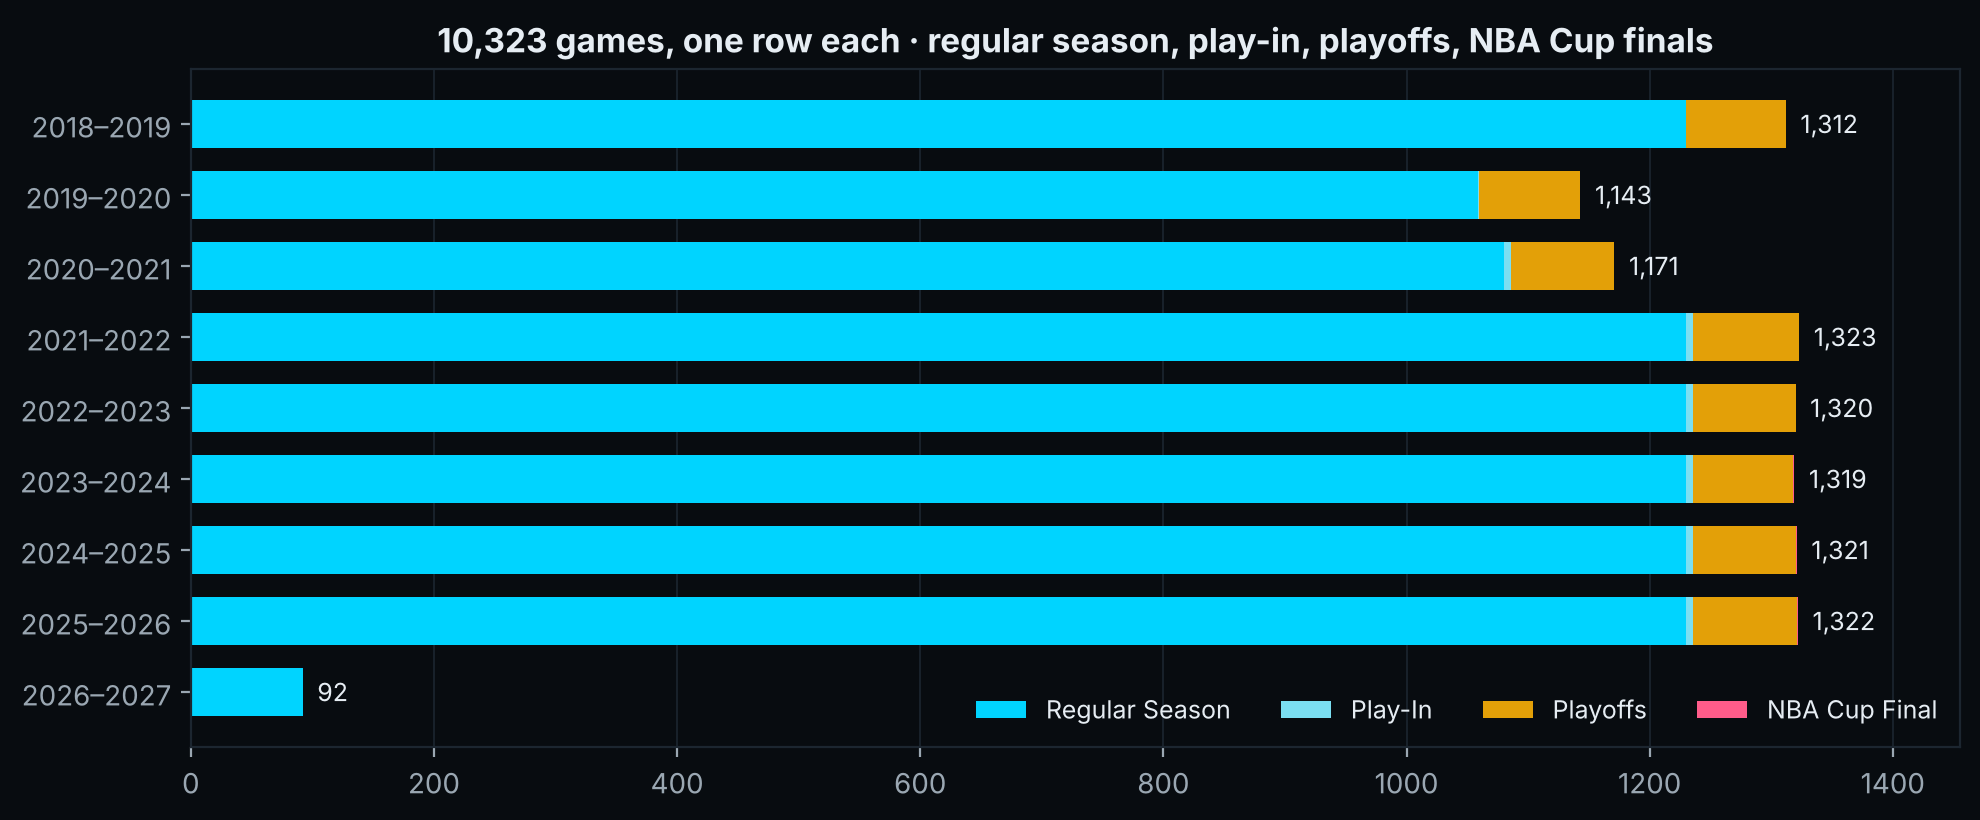

In [5]:
st = pd.crosstab(F["Season"], F["Stage"]).reindex(columns=["Regular Season", "Play-In", "Playoffs", "NBA Cup Final"], fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.2))
left = np.zeros(len(st))
colors = {"Regular Season": CYAN, "Play-In": "#7bdff2", "Playoffs": AMBER, "NBA Cup Final": "#ff5c8a"}
for stage in st.columns:
    ax.barh(range(len(st)), st[stage], left=left, color=colors[stage], height=0.68, label=stage, zorder=2)
    left += st[stage].to_numpy()
for i, total in enumerate(left):
    ax.text(total + 12, i, f"{int(total):,}", va="center", fontsize=9, color=FG)
ax.set_yticks(range(len(st)), [s.replace("/", "–") for s in st.index])
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, left.max() * 1.1)
ax.legend(loc="lower right", ncol=4, fontsize=9)
ax.set_title(f"{len(F):,} games, one row each · regular season, play-in, playoffs, NBA Cup finals")
plt.tight_layout(); plt.show()

## 4 · Who is in the file, and from when

The listing gives the first game with a price for each source, closing and opening, and the README gives the
share of games covered season by season. Recomputed here from the price columns.

In [6]:
def first_month(src, phase):
    cols = [c for c in PRICES if c.startswith(src + "_") and c.endswith("_" + phase)]
    has = F[cols].notna().any(axis=1)
    return F.loc[has, "Game_ID"].iloc[0] if has.any() else None

first = pd.DataFrame({ph: {s: first_month(s, ph) for s in SOURCES} for ph in ("Close", "Open")})
month = first.apply(lambda col: col.str[:4] + "-" + col.str[4:6])
check("first closing price, month by month, as listed", month["Close"].to_dict() == CLAIMS["first_close"])
check("first opening price, month by month, as listed", month["Open"].to_dict() == CLAIMS["first_open"])
check("FanDuel starts 8 Nov 2018, DraftKings 30 Jan 2019, Hard Rock 14 Mar 2025, Fanatics 21 Oct 2025",
      all(first.loc[s, "Close"][:8] == d for s, d in CLAIMS["first_close_day"].items()))
first.rename(index=NAME).rename(columns={"Close": "First closing price", "Open": "First opening price"})

PASS  first closing price, month by month, as listed
PASS  first opening price, month by month, as listed
PASS  FanDuel starts 8 Nov 2018, DraftKings 30 Jan 2019, Hard Rock 14 Mar 2025, Fanatics 21 Oct 2025


,First closing price,First opening price
Pinnacle,20181016_PHI_BOS,20181016_PHI_BOS
Bet365,20181016_PHI_BOS,20181016_PHI_BOS
FanDuel,20181108_HOU_OKC,20200730_LAC_LAL
DraftKings,20190130_CHA_BOS,20200730_LAC_LAL
BetMGM,20200803_DEN_OKC,20201222_LAC_LAL
Caesars,20200213_LAC_BOS,20200730_LAC_LAL
BetRivers,20191022_NOP_TOR,20261020_BOS_DET
BetOnline,20200730_UTA_NOP,20200730_LAC_LAL
theScore,20231114_ORL_BKN,20231114_DAL_NOP
Fanatics,20251021_HOU_OKC,20261024_MIA_CHA


PASS  closing moneyline coverage, season by season, as in the README
PASS  opening moneyline coverage, season by season, as in the README


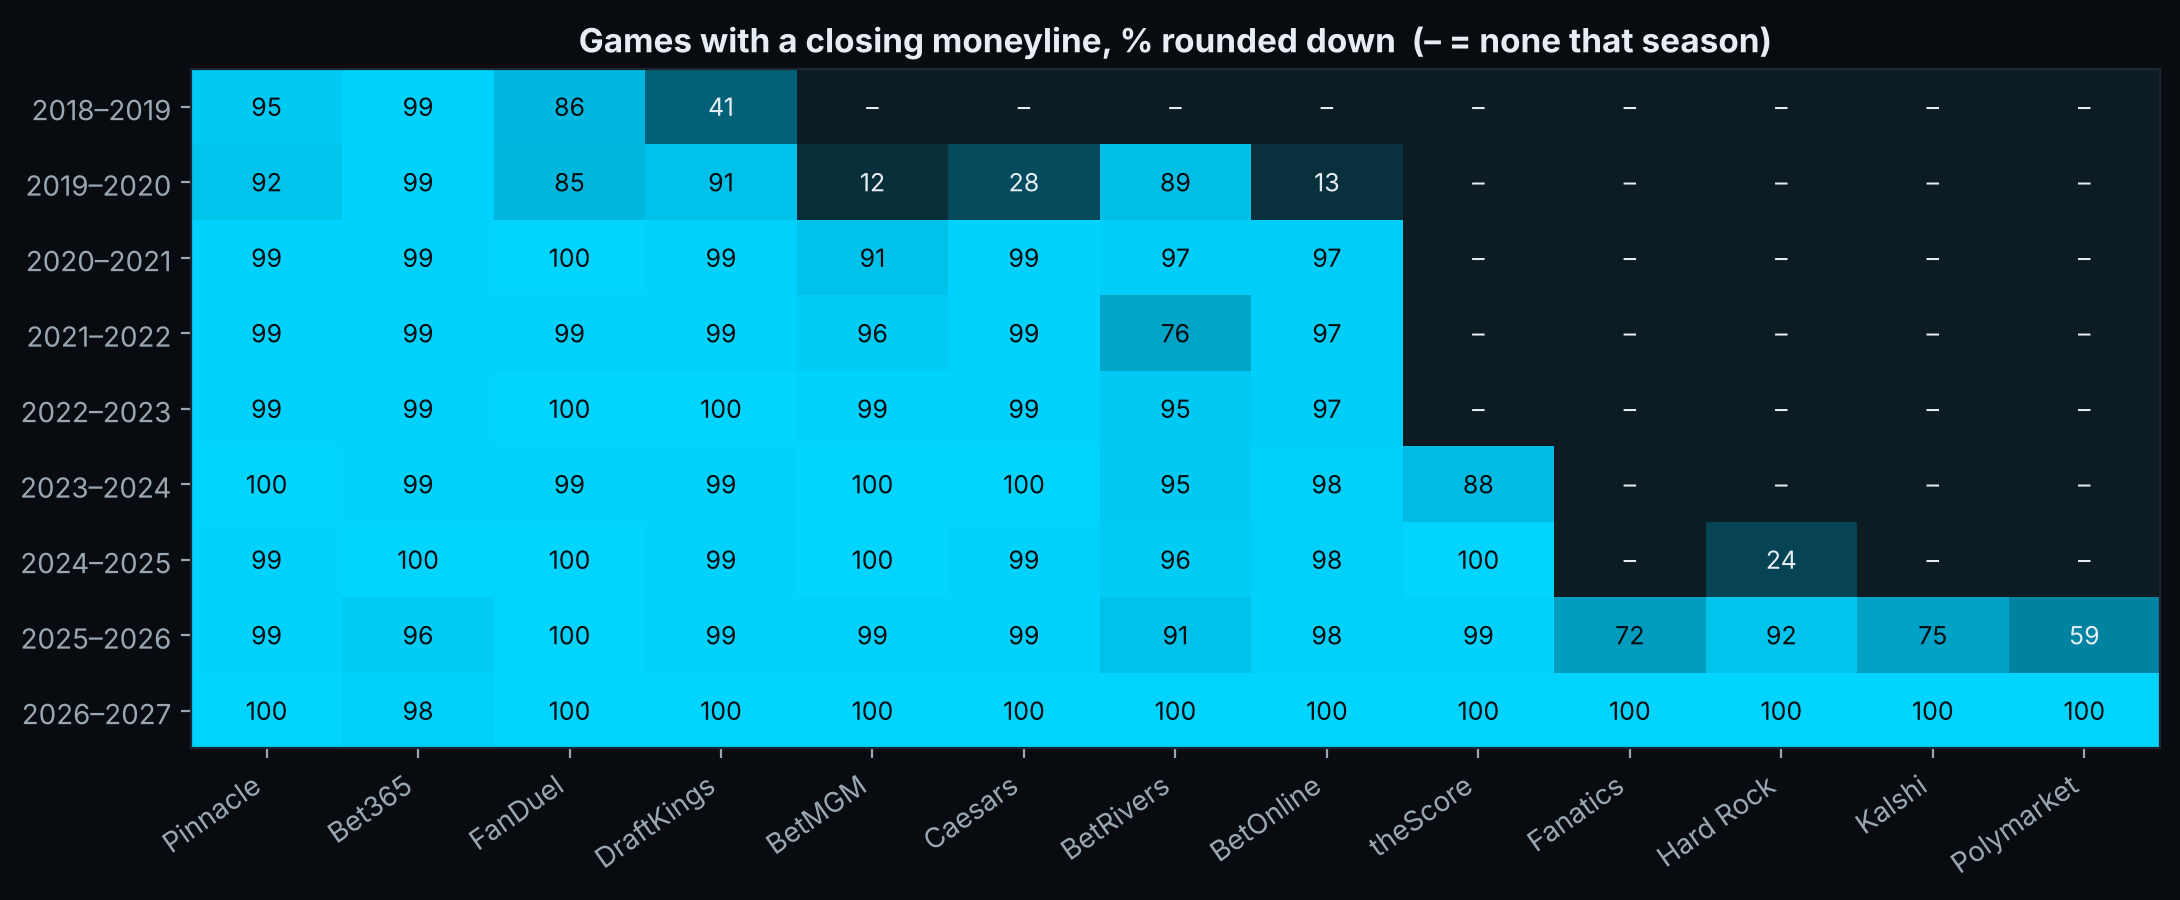

,Pinnacle,Bet365,FanDuel,DraftKings,BetMGM,Caesars,BetRivers,BetOnline,theScore,Fanatics,Hard Rock,Kalshi,Polymarket
"Opening moneyline, %",,,,,,,,,,,,,
2018/2019,99,99,–,–,–,–,–,–,–,–,–,–,–
2019/2020,96,99,12,11,–,11,–,11,–,–,–,–,–
2020/2021,98,98,91,81,80,82,–,80,–,–,–,–,–
2021/2022,99,99,92,88,90,72,–,76,–,–,–,–,–
2022/2023,99,98,93,92,89,87,–,79,–,–,–,–,–
2023/2024,99,99,95,95,89,89,–,80,82,–,–,–,–
2024/2025,99,99,96,96,92,90,–,79,94,–,–,–,–
2025/2026,99,99,96,96,90,93,–,81,90,–,–,–,–
2026/2027,100,100,100,88,94,97,100,100,100,66,100,94,95


In [7]:
def coverage(suffix):
    return {s: {b: math.floor(100 * x[f"{b}{suffix}"].notna().mean()) for b in SOURCES}
            for s, x in F.groupby("Season")}
close_cov, open_cov = coverage("_ML_Home_Close"), coverage("_ML_Home_Open")
diff = [f"{s} {b}" for s in close_cov for b in SOURCES if close_cov[s][b] != CLAIMS["close_cov"][s][b]]
check("closing moneyline coverage, season by season, as in the README", not diff, ", ".join(diff[:6]))
diff = [f"{s} {b}" for s in open_cov for b in SOURCES if open_cov[s][b] != CLAIMS["open_cov"][s][b]]
check("opening moneyline coverage, season by season, as in the README", not diff, ", ".join(diff[:6]))

cov = pd.DataFrame(close_cov).T[SOURCES]
cmap = LinearSegmentedColormap.from_list("cyan", ["#0d1b22", "#00708c", CYAN])
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.imshow(cov.to_numpy(), aspect="auto", cmap=cmap, vmin=0, vmax=100)
ax.set_xticks(range(len(SOURCES)), [NAME.get(s, s) for s in SOURCES], rotation=35, ha="right")
ax.set_yticks(range(len(cov)), [s.replace("/", "–") for s in cov.index])
ax.grid(False)
for i in range(cov.shape[0]):
    for j in range(cov.shape[1]):
        v = cov.iat[i, j]
        ax.text(j, i, "–" if v == 0 else str(v), ha="center", va="center", fontsize=9,
                color=BG if v > 60 else FG)
ax.set_title("Games with a closing moneyline, % rounded down  (– = none that season)")
plt.tight_layout(); plt.show()
pd.DataFrame(open_cov).T[SOURCES].rename(columns=NAME).replace(0, "–").rename_axis("Opening moneyline, %")

## 5 · Opening, closing, tip-off

The opening price is the first price recorded for the game, the closing price the last pre-game price. The
README sets hard limits: no opening price after the scheduled tip-off, no closing price older than 12 hours
before it or stamped more than 30 minutes after it. Then the README's table of early closing prices, season by season and book by book, and Pinnacle's late closes.

In [8]:
opens = [c for c in ODDS if c.endswith("_Open_Time")]
closes = [c for c in ODDS if c.endswith("_Close_Time")]
dc = pd.concat([minutes_vs_tipoff(c) for c in closes], axis=1)
do = pd.concat([minutes_vs_tipoff(c) for c in opens], axis=1)
check("no opening price is stamped after the scheduled tip-off", (do.max().max() <= 0), f"latest {do.max().max():.0f} min")
check(f"no closing price older than {CLAIMS['oldest_close_hours']} h before tip-off",
      -dc.min().min() <= 60 * CLAIMS["oldest_close_hours"], f"oldest {-dc.min().min() / 60:.2f} h before")
check(f"no closing price stamped more than {CLAIMS['latest_close_minutes']} min after tip-off",
      dc.max().max() <= CLAIMS["latest_close_minutes"], f"latest {dc.max().max():.1f} min after")
inverted = sum(int((ts(o) > ts(o.replace("_Open_", "_Close_"))).sum()) for o in opens)
check("an opening price is never recorded after the closing price of the same book and market", inverted == 0)
lonely = sum(int((F[o].notna() & F[o.replace("_Open_", "_Close_")].isna()).sum()) for o in opens)
check(f"{CLAIMS['open_without_close']:,} markets have an opening price and no closing price",
      lonely == CLAIMS["open_without_close"], f"{lonely:,}")
x = F["Season"] == "2026/2027"
early = pd.concat([minutes_vs_tipoff(f"Bet365_{m}_Close_Time")[x] < -15 for m in ("ML", "Spread", "Total")], axis=1).any(axis=1)
check(f"2026-27: a Bet365 closing price more than 15 min before tip-off in {CLAIMS['bet365_early_close_2026_27']} of 92 games",
      early.sum() == CLAIMS["bet365_early_close_2026_27"], f"{early.sum()}")

med = {}
for s in SOURCES:
    m = minutes_vs_tipoff(f"{s}_ML_Close_Time")
    if s == "Pinnacle":
        m = m[KICK >= RESTART]
    med[s] = m.dropna()
got = {s: int(round(v.median())) for s, v in med.items()}
check("median closing moneyline time vs tip-off, as in the README (Pinnacle from the 2020 restart)",
      got == CLAIMS["median_close_min"], " · ".join(f"{NAME.get(s, s)} {v:+d}" for s, v in got.items()))

# before the March 2020 pause, the closing prices can be old: median age at the scheduled tip-off
PAUSE = pd.Timestamp("2020-03-12", tz="UTC")
periods = {"2018-19": F["Season"] == "2018/2019",
           "2019-20 before the pause": (F["Season"] == "2019/2020") & (KICK < PAUSE),
           "2020 bubble": (F["Season"] == "2019/2020") & (KICK >= RESTART)}
age = lambda s, p: (-minutes_vs_tipoff(f"{s}_ML_Close_Time")[periods[p]]).median()
got_m = {k: int(round(age(*k))) for k in CLAIMS["median_age_minutes"]}
got_h = {k: round(age(*k) / 60, 0 if CLAIMS["median_age_hours"][k] == int(CLAIMS["median_age_hours"][k]) else 1)
         for k in CLAIMS["median_age_hours"]}
check("median age of the closing moneyline, as listed: FanDuel 19 min in 2018-19; Caesars 50, DraftKings 70, BetRivers 72 min "
      "and FanDuel 5 h before the pause; BetMGM 92 min in the bubble; Pinnacle 5.4 h and 5.1 h",
      got_m == CLAIMS["median_age_minutes"] and got_h == CLAIMS["median_age_hours"],
      " · ".join(f"{s} {p} {v} min" for (s, p), v in got_m.items()) + " · "
      + " · ".join(f"{s} {p} {v} h" for (s, p), v in got_h.items()))

PASS  no opening price is stamped after the scheduled tip-off   [latest -5 min]
PASS  no closing price older than 12 h before tip-off   [oldest 12.00 h before]
PASS  no closing price stamped more than 30 min after tip-off   [latest 29.6 min after]


PASS  an opening price is never recorded after the closing price of the same book and market
PASS  1,182 markets have an opening price and no closing price   [1,182]
PASS  2026-27: a Bet365 closing price more than 15 min before tip-off in 78 of 92 games   [78]
PASS  median closing moneyline time vs tip-off, as in the README (Pinnacle from the 2020 restart)   [Pinnacle +9 · Bet365 -2 · FanDuel +1 · DraftKings +1 · BetMGM +1 · Caesars +1 · BetRivers -16 · BetOnline +1 · theScore +1 · Fanatics +1 · Hard Rock +1 · Kalshi +1 · Polymarket +1]
PASS  median age of the closing moneyline, as listed: FanDuel 19 min in 2018-19; Caesars 50, DraftKings 70, BetRivers 72 min and FanDuel 5 h before the pause; BetMGM 92 min in the bubble; Pinnacle 5.4 h and 5.1 h   [FanDuel 2018-19 19 min · Caesars 2019-20 before the pause 50 min · DraftKings 2019-20 before the pause 70 min · BetRivers 2019-20 before the pause 72 min · BetMGM 2020 bubble 92 min · FanDuel 2019-20 before the pause 5.0 h · Pinnacle 2018-19

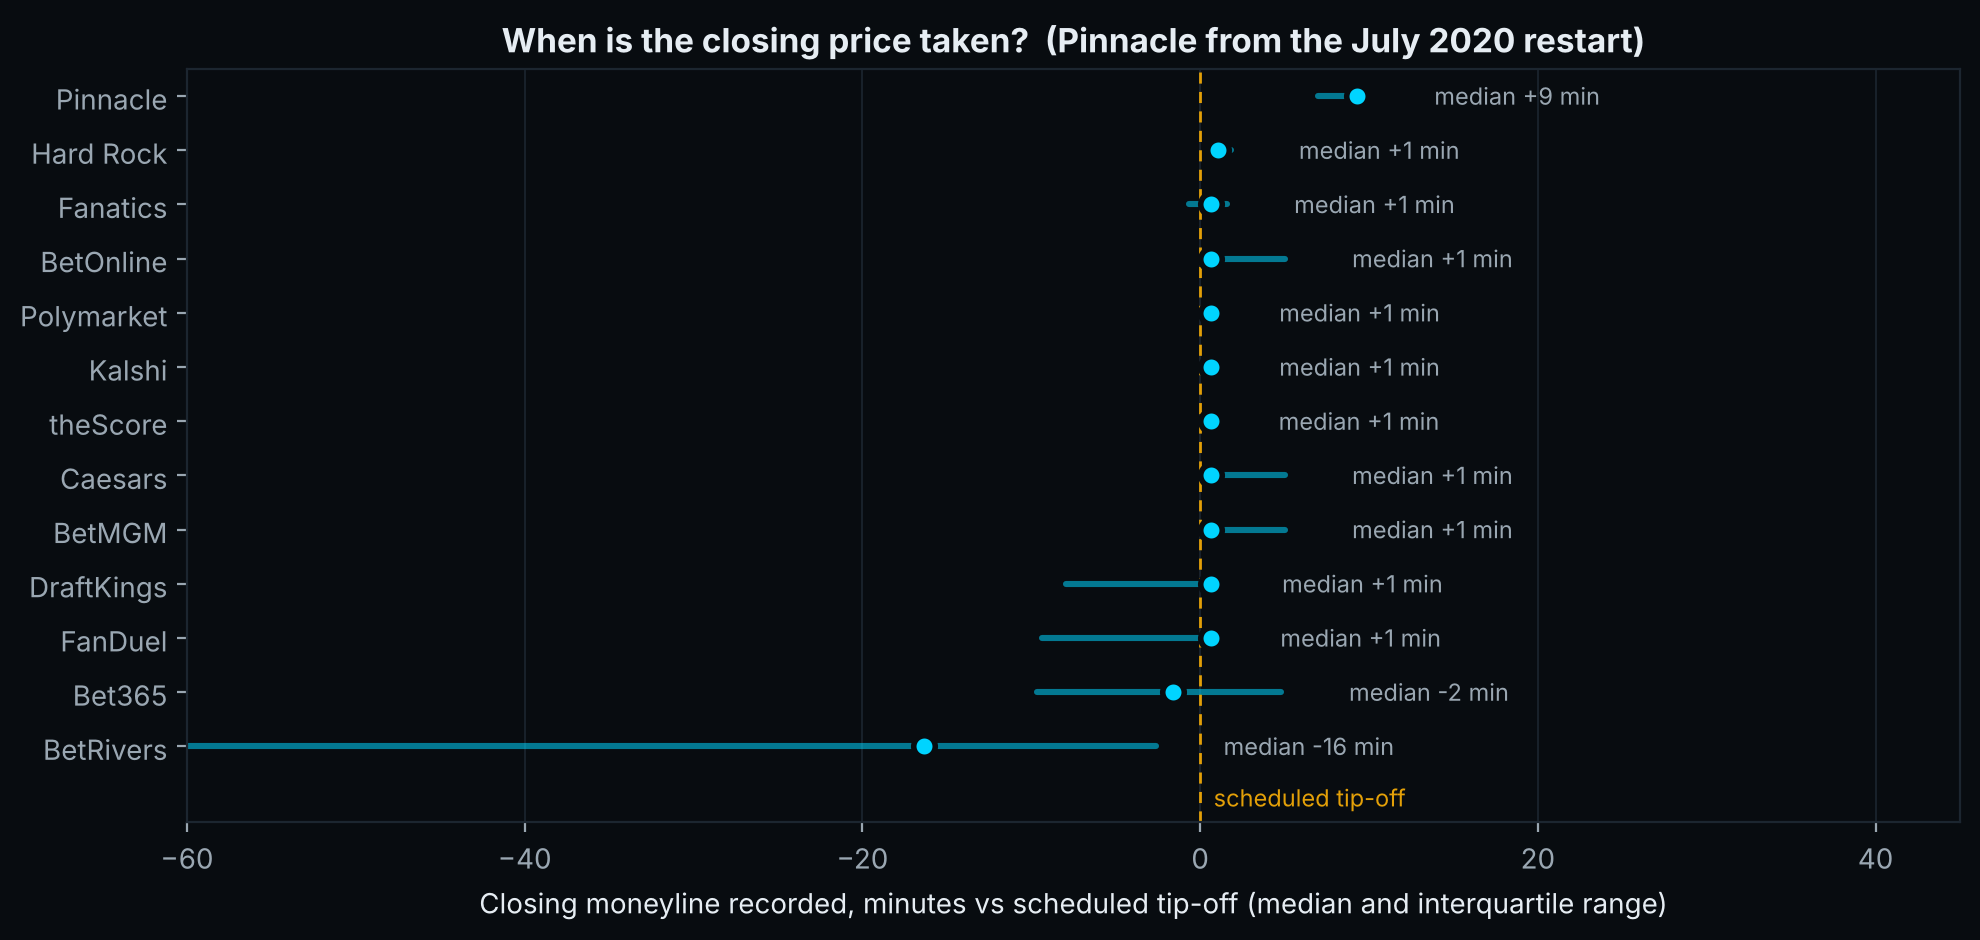

In [9]:
order = sorted(SOURCES, key=lambda s: med[s].median())
fig, ax = plt.subplots(figsize=(10, 4.8))
for i, s in enumerate(order):
    q1, q2, q3 = np.percentile(med[s], [25, 50, 75])
    ax.plot([q1, q3], [i, i], color=CYAN, linewidth=2.2, alpha=0.55, solid_capstyle="round")
    ax.scatter([q2], [i], s=60, color=CYAN, edgecolor=BG, linewidth=2, zorder=3)
    ax.text(max(q3, q2) + 4, i, f"median {q2:+.0f} min", va="center", fontsize=8.5, color=FG2)
ax.axvline(0, color=AMBER, linewidth=1, linestyle=(0, (4, 3)))
ax.text(0.8, -0.95, "scheduled tip-off", color=AMBER, fontsize=8.5, va="center")
ax.set_ylim(-1.4, len(order) - 0.5)
ax.set_yticks(range(len(order)), [NAME.get(s, s) for s in order])
ax.set_xlim(-60, 45); ax.grid(axis="y", visible=False)
ax.set_xlabel("Closing moneyline recorded, minutes vs scheduled tip-off (median and interquartile range)")
ax.set_title("When is the closing price taken?  (Pinnacle from the July 2020 restart)")
plt.tight_layout(); plt.show()

In [10]:
# README: per season, the games where at least one moneyline, spread or total closing price of the book is
# stamped more than 15 minutes before the scheduled tip-off
early_tbl = {}
for b in BOOKS:
    e = pd.concat([minutes_vs_tipoff(f"{b}_{mk}_Close_Time") < -15 for mk in ("ML", "Spread", "Total")], axis=1).any(axis=1)
    early_tbl[b] = e.groupby(F["Season"]).sum().astype(int).to_dict()
got_early = {s: {b: early_tbl[b].get(s, 0) for b in BOOKS} for s in CLAIMS["early_close"]}
same_cells = sum(got_early[s][b] == CLAIMS["early_close"][s][b] for s in got_early for b in BOOKS)
check("the README table of games with a closing price more than 15 min before tip-off, every season and book",
      got_early == CLAIMS["early_close"], f"{same_cells} of {len(BOOKS) * len(CLAIMS['early_close'])} cells equal")
n_late, max_late = CLAIMS["pinnacle_close_after_10_min"]
late_pin = minutes_vs_tipoff("Pinnacle_ML_Close_Time")
check(f"Pinnacle's closing moneyline is stamped more than 10 min after the scheduled tip-off in {n_late:,} games, "
      f"{max_late} min at most", (late_pin > 10).sum() == n_late and late_pin.max() <= max_late,
      f"{(late_pin > 10).sum():,} games, {late_pin.max():.1f} min at most")
pd.DataFrame(got_early).T.rename(columns=NAME).replace(0, "–").rename_axis("Closing price > 15 min before tip-off")

PASS  the README table of games with a closing price more than 15 min before tip-off, every season and book   [99 of 99 cells equal]
PASS  Pinnacle's closing moneyline is stamped more than 10 min after the scheduled tip-off in 1,246 games, 27 min at most   [1,246 games, 26.7 min at most]


,Pinnacle,Bet365,FanDuel,DraftKings,BetMGM,Caesars,BetRivers,BetOnline,theScore,Fanatics,Hard Rock
Closing price > 15 min before tip-off,,,,,,,,,,,
2018/2019,1260,310,753,154,–,–,–,–,–,–,–
2019/2020,920,80,973,838,131,269,966,3,–,–,–
2020/2021,14,36,243,34,144,357,1026,5,–,–,–
2021/2022,1,82,18,34,115,134,930,20,–,–,–
2022/2023,9,117,43,37,49,35,813,13,–,–,–
2023/2024,17,18,19,17,52,22,671,5,30,–,–
2024/2025,10,16,13,7,27,36,727,3,16,–,209
2025/2026,330,78,4,3,11,4,1,7,5,260,3
2026/2027,–,78,–,–,–,1,–,–,–,–,–


## 6 · Are these real market prices?

A real closing line is better informed than the opening one: its implied probabilities should predict the
winner better. Probabilities are de-margined proportionally; lower log-loss is better. Compare open and close
**within a book**, on the games where the book has both, from the July 2020 restart.

In [11]:
home_won = (F["Winner"] == "Home").to_numpy()
rows = []
for b in BOOKS + ["Kalshi", "Polymarket"]:
    o = F[[f"{b}_ML_Home_Open", f"{b}_ML_Away_Open"]].to_numpy(float)
    c = F[[f"{b}_ML_Home_Close", f"{b}_ML_Away_Close"]].to_numpy(float)
    ok = ~np.isnan(o).any(1) & ~np.isnan(c).any(1) & (KICK >= RESTART).to_numpy()
    if ok.sum() < 50:
        continue
    def logloss(p):
        p = np.clip(p, 1e-6, 1 - 1e-6)
        return -np.mean(np.where(home_won[ok], np.log(p), np.log(1 - p)))
    po, pc = no_vig(o[ok, 0], o[ok, 1]), no_vig(c[ok, 0], c[ok, 1])
    rows.append((NAME.get(b, b), int(ok.sum()), logloss(po), logloss(pc)))
LL = pd.DataFrame(rows, columns=["Source", "Games", "Log-loss open", "Log-loss close"]).set_index("Source")
check("the closing moneyline predicts the winner better than the opening one, for every book",
      (LL.loc[[NAME.get(b, b) for b in BOOKS if NAME.get(b, b) in LL.index], "Log-loss close"]
       < LL.loc[[NAME.get(b, b) for b in BOOKS if NAME.get(b, b) in LL.index], "Log-loss open"]).all())
LL.style.format({"Games": "{:,}", "Log-loss open": "{:.4f}", "Log-loss close": "{:.4f}"})

PASS  the closing moneyline predicts the winner better than the opening one, for every book


,Games,Log-loss open,Log-loss close
Source,,,
Pinnacle,"7,984",0.6055,0.5993
Bet365,"7,932",0.6082,0.5999
FanDuel,"7,569",0.6073,0.6004
DraftKings,"7,356",0.6078,0.6011
BetMGM,"6,994",0.6047,0.5988
Caesars,"6,911",0.6048,0.6005
BetRivers,92,0.5805,0.5666
BetOnline,"6,412",0.6025,0.6010
theScore,"3,628",0.5885,0.5816


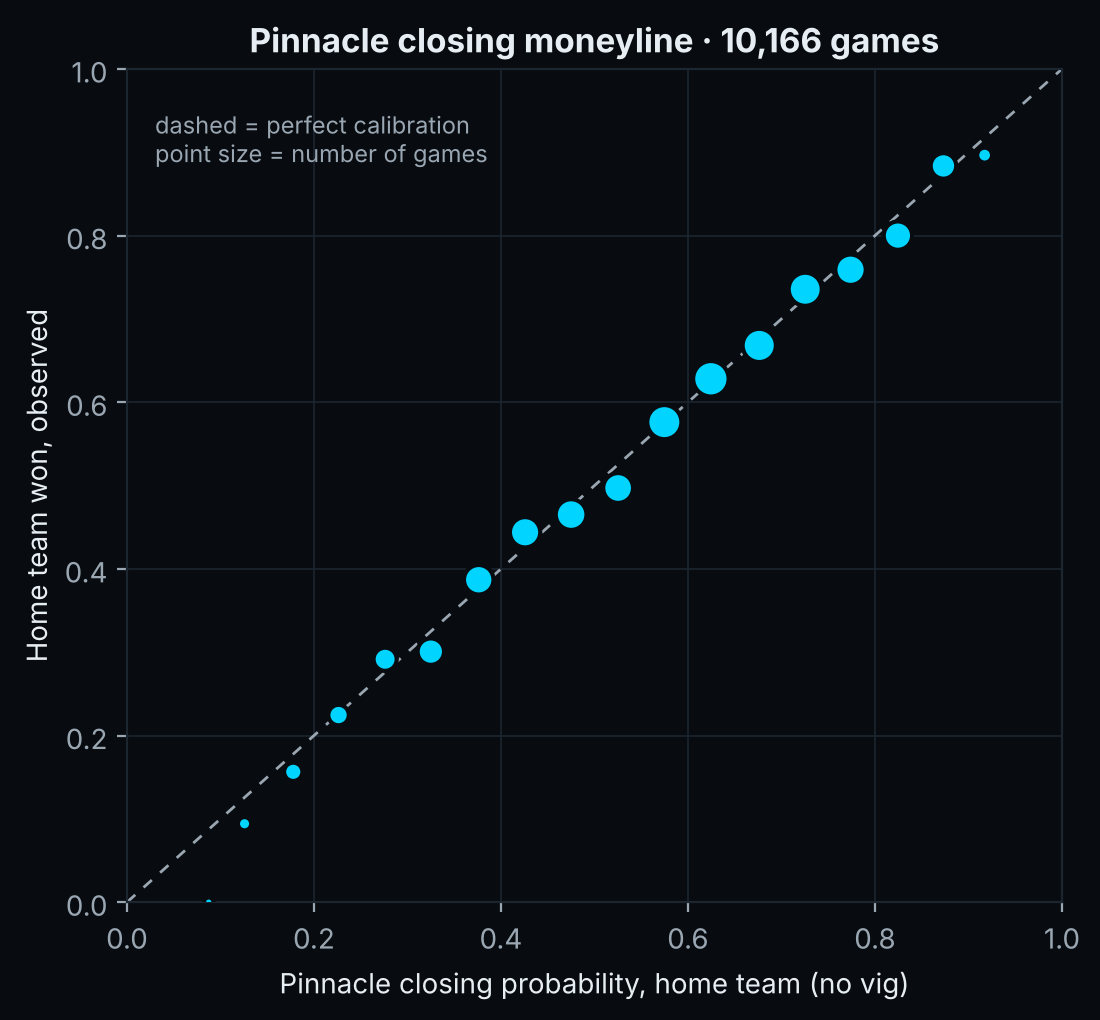

In [12]:
# Pinnacle closing moneyline: predicted probability of the home team vs observed frequency
c = F[["Pinnacle_ML_Home_Close", "Pinnacle_ML_Away_Close"]].to_numpy(float)
ok = ~np.isnan(c).any(1)
cal = pd.DataFrame({"p": no_vig(c[ok, 0], c[ok, 1]), "hit": home_won[ok]})
cal["bin"] = pd.cut(cal["p"], np.arange(0, 1.0001, 0.05))
cb = cal.groupby("bin", observed=True).agg(p=("p", "mean"), freq=("hit", "mean"), n=("hit", "size"))
cb = cb[cb["n"] >= 40]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=FG2, linewidth=1, linestyle=(0, (4, 4)))
ax.scatter(cb["p"], cb["freq"], s=np.clip(cb["n"] / 6, 12, 180), color=CYAN, edgecolor=BG, linewidth=1.5, zorder=3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Pinnacle closing probability, home team (no vig)"); ax.set_ylabel("Home team won, observed")
ax.set_title(f"Pinnacle closing moneyline · {ok.sum():,} games")
ax.text(0.03, 0.95, "dashed = perfect calibration\npoint size = number of games", fontsize=8.5, color=FG2, va="top")
plt.tight_layout(); plt.show()

## 7 · Pinnacle team totals

One over/under per team, opening and closing, from Pinnacle only: 31 December 2020 to the 2026 Finals.

In [13]:
tt = [c for c in PRICES + [c for c in ODDS if "_Line_" in c] if c.startswith("Pinnacle_Team_Total_")]
has = F[tt].notna().any(axis=1)
both = F["Pinnacle_Team_Total_Home_Line_Close"].notna() & F["Pinnacle_Team_Total_Away_Line_Close"].notna()
check(f"{CLAIMS['team_totals_games']:,} games with a Pinnacle team total, {CLAIMS['team_totals_both_closing']:,} with a closing one for both teams",
      has.sum() == CLAIMS["team_totals_games"] and both.sum() == CLAIMS["team_totals_both_closing"], f"{has.sum():,} / {both.sum():,}")
check("from 31 Dec 2020 to the 2026 Finals, none in 2026-27",
      F.loc[has, "Game_ID"].iloc[0].startswith(CLAIMS["team_totals_first"]) and F.loc[has, "Game_ID"].iloc[-1] == CLAIMS["team_totals_last"]
      and not has[F["Season"] == "2026/2027"].any(), f"{F.loc[has, 'Game_ID'].iloc[0]} to {F.loc[has, 'Game_ID'].iloc[-1]}")
y = F["Season"] == "2025/2026"
share = {sd: math.floor(100 * F.loc[y, f"Pinnacle_Team_Total_{sd}_Line_Close"].notna().mean()) for sd in ("Home", "Away")}
check("2025-26: a closing team total for the home team in 83% of the games, 86% for the away team",
      share == CLAIMS["team_totals_2025_26_closing"], f"{share}")
gap = (F["Pinnacle_Team_Total_Home_Line_Close"] + F["Pinnacle_Team_Total_Away_Line_Close"] - F["Pinnacle_Total_Line_Close"]).dropna()
print(f"Home + away team totals minus the game total, at the close, {len(gap):,} games: median {gap.median():+.1f} points, "
      f"90% between {gap.quantile(0.05):+.1f} and {gap.quantile(0.95):+.1f}")
tt_cov = {s: {f"{sd} {ph.lower()}": math.floor(100 * x[f"Pinnacle_Team_Total_{sd}_Line_{ph}"].notna().mean())
              for ph in ("Open", "Close") for sd in ("Home", "Away")} for s, x in F.groupby("Season")}
listed = {s: v for s, v in tt_cov.items() if s in CLAIMS["team_total_cov"]}
check("the README table of Pinnacle team-total coverage, 2020-21 to 2025-26, opening and closing, both teams; "
      "none in the other seasons",
      listed == CLAIMS["team_total_cov"] and all(sum(v.values()) == 0 for s, v in tt_cov.items() if s not in listed),
      " · ".join(f"{s[:4]}-{s[7:]} " + "/".join(str(n) for n in v.values()) for s, v in listed.items()))

PASS  7,673 games with a Pinnacle team total, 7,381 with a closing one for both teams   [7,673 / 7,381]
PASS  from 31 Dec 2020 to the 2026 Finals, none in 2026-27   [20201231_PHI_ORL to 20260613_NYK_SAS]
PASS  2025-26: a closing team total for the home team in 83% of the games, 86% for the away team   [{'Home': 83, 'Away': 86}]
Home + away team totals minus the game total, at the close, 7,361 games: median +0.0 points, 90% between -1.5 and +1.0
PASS  the README table of Pinnacle team-total coverage, 2020-21 to 2025-26, opening and closing, both teams; none in the other seasons   [2020-21 94/94/94/94 · 2021-22 100/100/99/99 · 2022-23 99/99/99/99 · 2023-24 99/99/98/98 · 2024-25 99/99/98/98 · 2025-26 96/96/83/86]


## 8 · Prediction markets next to the books

Kalshi and Polymarket carry the moneyline only, written as American odds. In 2026-27 they often close at the
same price; each keeps its own quote.

In [14]:
x = F[F["Season"] == "2026/2027"]
same = ((x["Kalshi_ML_Home_Close"] == x["Polymarket_ML_Home_Close"]) & (x["Kalshi_ML_Away_Close"] == x["Polymarket_ML_Away_Close"]))
check(f"2026-27: Kalshi and Polymarket close at the same price on both sides in {CLAIMS['kalshi_polymarket_same_close_2026_27']} of 92 games",
      same.sum() == CLAIMS["kalshi_polymarket_same_close_2026_27"], f"{same.sum()}")
ok = F[["Kalshi_ML_Home_Close", "Kalshi_ML_Away_Close", "Pinnacle_ML_Home_Close", "Pinnacle_ML_Away_Close"]].notna().all(axis=1)
k = no_vig(F.loc[ok, "Kalshi_ML_Home_Close"], F.loc[ok, "Kalshi_ML_Away_Close"])
p = no_vig(F.loc[ok, "Pinnacle_ML_Home_Close"], F.loc[ok, "Pinnacle_ML_Away_Close"])
print(f"Kalshi vs Pinnacle at the close, no-vig probability of the home team: mean absolute gap "
      f"{np.mean(np.abs(k - p)):.3f} on {ok.sum():,} games")

PASS  2026-27: Kalshi and Polymarket close at the same price on both sides in 63 of 92 games   [63]
Kalshi vs Pinnacle at the close, no-vig probability of the home team: mean absolute gap 0.007 on 1,087 games


## 9 · The games on the listing's images

The images of the Gumroad listing are drawn from the file. The games they show, recomputed: images 1 to 5 and 7 (the figures of images 6 and 8 are checked in sections 2 to 4).

In [15]:
G = F.set_index("Game_ID")
gid, n_src, secs = CLAIMS["same_second_game"]
r = G.loc[gid]
t = {s: r[f"{s}_ML_Close_Time"] for s in SOURCES if pd.notna(r[f"{s}_ML_Close_Time"])}
gap_s = (pd.Timestamp(r["Kickoff_UTC"]) - pd.Timestamp(list(t.values())[0])).total_seconds()
check(f"Celtics at Magic, 1 Nov 2026: all {n_src} closing moneylines recorded at the same second, {secs} s before tip-off",
      len(t) == n_src and len(set(t.values())) == 1 and gap_s == secs, f"{list(t.values())[0]}, tip-off {r['Kickoff_UTC']}")
pd.DataFrame({"ML home open": [r[f"{s}_ML_Home_Open"] for s in SOURCES], "ML away open": [r[f"{s}_ML_Away_Open"] for s in SOURCES],
              "ML home close": [r[f"{s}_ML_Home_Close"] for s in SOURCES], "ML away close": [r[f"{s}_ML_Away_Close"] for s in SOURCES],
              "Closed at (UTC)": [r[f"{s}_ML_Close_Time"] for s in SOURCES]},
             index=[NAME.get(s, s) for s in SOURCES]).astype({c: "Int64" for c in ["ML home open", "ML away open", "ML home close", "ML away close"]})

PASS  Celtics at Magic, 1 Nov 2026: all 13 closing moneylines recorded at the same second, 29 s before tip-off   [2026-11-01T20:29:31Z, tip-off 2026-11-01T20:30:00Z]


,ML home open,ML away open,ML home close,ML away close,Closed at (UTC)
Pinnacle,224,-265,232,-267,2026-11-01T20:29:31Z
Bet365,215,-265,240,-300,2026-11-01T20:29:31Z
FanDuel,205,-250,245,-300,2026-11-01T20:29:31Z
DraftKings,210,-263,230,-286,2026-11-01T20:29:31Z
BetMGM,220,-275,230,-295,2026-11-01T20:29:31Z
Caesars,210,-260,222,-278,2026-11-01T20:29:31Z
BetRivers,200,-265,240,-315,2026-11-01T20:29:31Z
BetOnline,207,-250,230,-280,2026-11-01T20:29:31Z
theScore,215,-260,230,-280,2026-11-01T20:29:31Z
Fanatics,210,-260,230,-285,2026-11-01T20:29:31Z


PASS  Lakers at Clippers, 28 Oct 2026: 9 books opened the Clippers at +5.5, 10 of 11 closed them as favourites   [9 at +5.5 · 10 of 11 favourites]


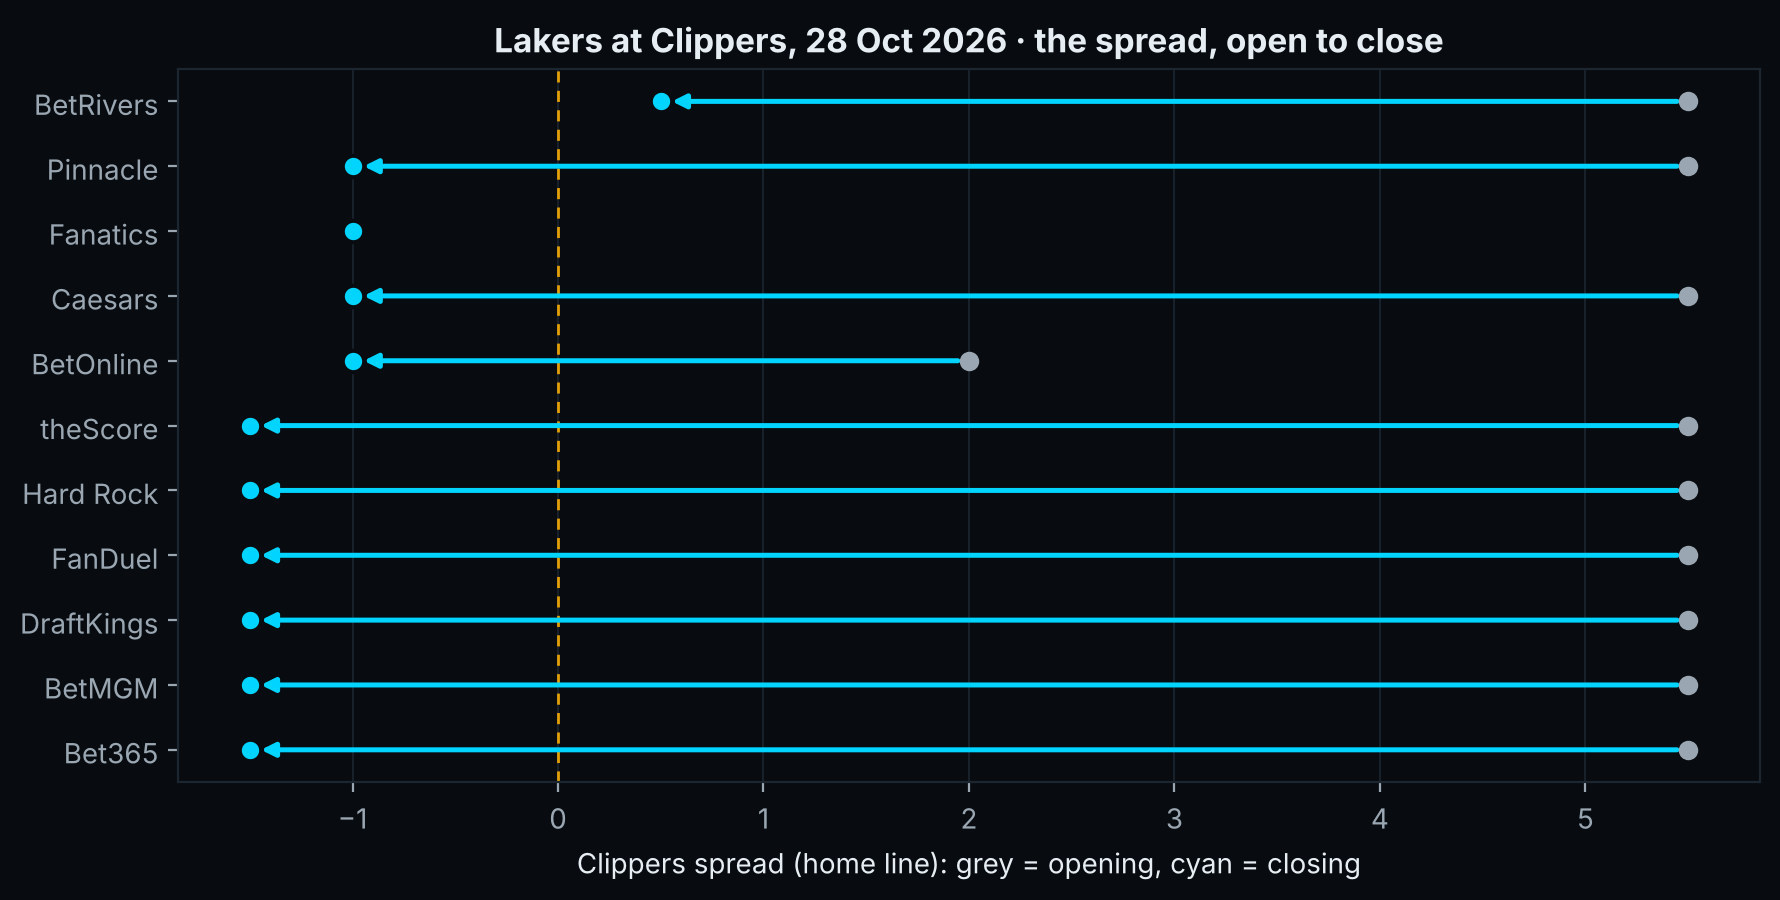

In [16]:
gid, line, n_at, n_fav, n_books = CLAIMS["spread_move_game"]
r = G.loc[gid]
bk = [b for b in BOOKS if pd.notna(r[f"{b}_Spread_Home_Line_Close"])]
op = {b: r[f"{b}_Spread_Home_Line_Open"] for b in bk}
cl = {b: r[f"{b}_Spread_Home_Line_Close"] for b in bk}
check(f"Lakers at Clippers, 28 Oct 2026: {n_at} books opened the Clippers at +{line}, {n_fav} of {n_books} closed them as favourites",
      sum(v == line for v in op.values()) == n_at and sum(v < 0 for v in cl.values()) == n_fav and len(cl) == n_books,
      f"{sum(v == line for v in op.values())} at +{line} · {sum(v < 0 for v in cl.values())} of {len(cl)} favourites")
order = sorted(bk, key=lambda b: (cl[b], b))
fig, ax = plt.subplots(figsize=(9, 4.6))
for i, b in enumerate(order):
    if pd.notna(op[b]):
        ax.annotate("", xy=(cl[b], i), xytext=(op[b], i),
                    arrowprops=dict(arrowstyle="-|>", color=CYAN, lw=1.8, shrinkA=4, shrinkB=4))
        ax.scatter([op[b]], [i], s=36, color=FG2, zorder=3)
    ax.scatter([cl[b]], [i], s=60, color=CYAN, edgecolor=BG, linewidth=1.5, zorder=4)
ax.axvline(0, color=AMBER, linewidth=1, linestyle=(0, (4, 3)))
ax.set_yticks(range(len(order)), [NAME.get(b, b) for b in order])
ax.set_xlabel("Clippers spread (home line): grey = opening, cyan = closing")
ax.set_title("Lakers at Clippers, 28 Oct 2026 · the spread, open to close"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [17]:
gid, score, tts = CLAIMS["finals_game"]
r = G.loc[gid]
check(f"2026 NBA Finals, Game 5, Knicks at Spurs: final {score[0]}-{score[1]}, Pinnacle team totals at the close "
      f"Spurs {tts[0]}, Knicks {tts[1]}",
      (r["Away_Score"], r["Home_Score"]) == score
      and (r["Pinnacle_Team_Total_Home_Line_Close"], r["Pinnacle_Team_Total_Away_Line_Close"]) == tts)
mk = pd.DataFrame({
    "ML Spurs": [r[f"{s}_ML_Home_Close"] for s in SOURCES],
    "ML Knicks": [r[f"{s}_ML_Away_Close"] for s in SOURCES],
    "Spread Spurs": [r.get(f"{s}_Spread_Home_Line_Close", np.nan) for s in SOURCES],
    "Total": [r.get(f"{s}_Total_Line_Close", np.nan) for s in SOURCES]}, index=[NAME.get(s, s) for s in SOURCES])
mk.astype({"ML Spurs": "Int64", "ML Knicks": "Int64"}).rename_axis("Closing prices")

PASS  2026 NBA Finals, Game 5, Knicks at Spurs: final 94-90, Pinnacle team totals at the close Spurs 110.5, Knicks 105.5


,ML Spurs,ML Knicks,Spread Spurs,Total
Closing prices,,,,
Pinnacle,-197,175,-5.5,215.5
Bet365,-200,165,-5.5,215.5
FanDuel,-200,168,-5.5,215.5
DraftKings,-192,160,-5.5,216.5
BetMGM,-200,165,-5.5,215.5
Caesars,-195,162,-5.5,215.5
BetRivers,-215,170,-5.5,215.5
BetOnline,-192,167,-5.5,215.5
theScore,-180,165,-5.5,216.5


In [18]:
img1 = {g: tuple(int(G.loc[g, f"{s}_ML_Home_Close"]) for s in ("FanDuel", "DraftKings", "BetMGM", "Caesars", "Pinnacle"))
        for g in CLAIMS["image_1_home_close"]}
check("image 1: the home team's closing moneyline at FanDuel, DraftKings, BetMGM, Caesars and Pinnacle, "
      "5 games of 31 Oct and 1 Nov 2026", img1 == CLAIMS["image_1_home_close"])
img5 = {g: tuple((int(G.loc[g, f"{s}_ML_Home_Close"]), int(G.loc[g, f"{s}_ML_Away_Close"]))
                 for s in ("Pinnacle", "DraftKings", "Kalshi", "Polymarket"))
        for g in CLAIMS["image_5_close_home_away"]}
check("image 5: the closing moneylines of Pinnacle, DraftKings, Kalshi and Polymarket, home and away, same 5 games",
      img5 == CLAIMS["image_5_close_home_away"])
cols3 = ["Pinnacle_Team_Total_Home_Line_Open", "Pinnacle_Team_Total_Home_Line_Close", "Home_Score",
         "Pinnacle_Team_Total_Away_Line_Open", "Pinnacle_Team_Total_Away_Line_Close", "Away_Score"]
img3 = [(g, *[float(G.loc[g, c]) if "_Line_" in c else int(G.loc[g, c]) for c in cols3])
        for g, *_ in CLAIMS["image_3_finals_2025"]]
check("image 3: the 2025 NBA Finals, Pinnacle team totals of both teams, opening and closing, and the points scored, "
      "all 7 games", img3 == CLAIMS["image_3_finals_2025"])
pd.DataFrame(img3, columns=["2025 Finals", "Home total, open", "Home total, close", "Home points",
                            "Away total, open", "Away total, close", "Away points"]).set_index("2025 Finals")

PASS  image 1: the home team's closing moneyline at FanDuel, DraftKings, BetMGM, Caesars and Pinnacle, 5 games of 31 Oct and 1 Nov 2026
PASS  image 5: the closing moneylines of Pinnacle, DraftKings, Kalshi and Polymarket, home and away, same 5 games
PASS  image 3: the 2025 NBA Finals, Pinnacle team totals of both teams, opening and closing, and the points scored, all 7 games


,"Home total, open","Home total, close",Home points,"Away total, open","Away total, close",Away points
2025 Finals,,,,,,
20250605_IND_OKC,119.5,119.5,110,110.5,109.5,111
20250608_IND_OKC,119.5,120.5,123,108.5,108.5,107
20250611_OKC_IND,111.5,110.5,116,116.5,115.5,107
20250613_OKC_IND,109.5,110.5,104,115.5,116.5,111
20250616_IND_OKC,116.5,116.5,120,107.5,106.5,109
20250619_OKC_IND,109.5,109.5,108,114.5,114.5,91
20250622_IND_OKC,111.5,111.5,103,103.5,104.5,91


## 10 · Said plainly, checked

The limits the listing states up front, recomputed. The last check goes beyond the listing and the README: it is
stated here so nobody discovers it after paying.

In [19]:
pre = KICK < RESTART
check("Pinnacle has no spread before the July 2020 restart",
      not F.loc[pre, [c for c in ODDS if c.startswith("Pinnacle_Spread_") and not c.endswith("_Time")]].notna().any().any())
us_open_pre = F.loc[KICK < pd.Timestamp("2020-07-30", tz="UTC"), [f"{b}_ML_Home_Open" for b in US]].notna().sum()
print("US books' opening moneylines before the 30 July 2020 restart:", us_open_pre[us_open_pre > 0].to_dict())
late_open = {b: F.loc[F["Season"] != "2026/2027", [c for c in PRICES if c.startswith(b + "_") and c.endswith("_Open")]].notna().any().any()
             for b in ("BetRivers", "Fanatics", "HardRock", "Kalshi", "Polymarket")}
check("BetRivers, Fanatics, Hard Rock, Kalshi and Polymarket have opening prices in 2026-27 only", not any(late_open.values()))
check("Kalshi and Polymarket carry the moneyline only",
      all(set(c.split("_")[1] for c in ODDS if c.startswith(s + "_")) == {"ML"} for s in ("Kalshi", "Polymarket")))

# NBA Finals: the last playoff series of each season
P = F[F["Stage"] == "Playoffs"].copy()
P["pair"] = [tuple(sorted(t)) for t in zip(P["Home_Team"], P["Away_Team"])]
finals = pd.concat([g[g["pair"] == g["pair"].iloc[-1]] for _, g in P.groupby("Season")])
finals = finals[pd.to_datetime(finals["Kickoff_UTC"], utc=True) >= RESTART]
us_open = finals[[c for c in PRICES if c.split("_")[0] in US and c.endswith("_Open")]].notna().any(axis=1)
others = P[(pd.to_datetime(P["Kickoff_UTC"], utc=True) >= RESTART) & ~P["Game_ID"].isin(finals["Game_ID"])]
others_open = others[[f"{b}_ML_Home_Open" for b in US]].notna().any(axis=1)
fc = CLAIMS["finals"]
got = {"games": len(finals), "with_us_opening": int(us_open.sum()),
       "bet365_opening": int(finals["Bet365_ML_Home_Open"].notna().sum()),
       "pinnacle_opening": int(finals["Pinnacle_ML_Home_Open"].notna().sum()),
       "other_playoff_games": len(others), "other_with_us_opening": int(others_open.sum())}
check(f"NBA Finals since the 2020 restart: US books' closing prices on every game, their opening prices on "
      f"{fc['with_us_opening']} of {fc['games']}; Bet365 opening on {fc['bet365_opening']}, Pinnacle on {fc['pinnacle_opening']}; "
      f"other playoff games: {fc['other_with_us_opening']} of {fc['other_playoff_games']} with a US opening moneyline",
      got == fc and finals[[f"{b}_ML_Home_Close" for b in US]].notna().any(axis=1).all(),
      " · ".join(f"{k} {v}" for k, v in got.items()))
age_h = {b: (-minutes_vs_tipoff(f"{b}_ML_Open_Time")).median() / 60 for b in BOOKS}
bo_st = (-pd.concat([minutes_vs_tipoff(f"BetOnline_{mk}_Open_Time") for mk in ("Spread", "Total")])).median() / 60
lo, hi = CLAIMS["opening_age_hours"]["other books ML"]
oth_age = {b: v for b, v in age_h.items() if b != "BetOnline"}
check(f"BetOnline's opening moneyline is recorded a median {CLAIMS['opening_age_hours']['BetOnline ML']} h before tip-off, "
      f"its spread and total {CLAIMS['opening_age_hours']['BetOnline spread and total']} h, the other books' opening "
      f"moneyline about a day ({lo} to {hi} h)",
      round(age_h["BetOnline"], 1) == CLAIMS["opening_age_hours"]["BetOnline ML"]
      and round(bo_st) == CLAIMS["opening_age_hours"]["BetOnline spread and total"]
      and all(lo <= v <= hi for v in oth_age.values()),
      f"BetOnline {age_h['BetOnline']:.2f} h, spread and total {bo_st:.2f} h · other books "
      f"{min(oth_age.values()):.1f} to {max(oth_age.values()):.1f} h")

PASS  Pinnacle has no spread before the July 2020 restart
US books' opening moneylines before the 30 July 2020 restart: {}
PASS  BetRivers, Fanatics, Hard Rock, Kalshi and Polymarket have opening prices in 2026-27 only
PASS  Kalshi and Polymarket carry the moneyline only


PASS  NBA Finals since the 2020 restart: US books' closing prices on every game, their opening prices on 3 of 40; Bet365 opening on 40, Pinnacle on 34; other playoff games: 530 of 550 with a US opening moneyline   [games 40 · with_us_opening 3 · bet365_opening 40 · pinnacle_opening 34 · other_playoff_games 550 · other_with_us_opening 530]
PASS  BetOnline's opening moneyline is recorded a median 2.7 h before tip-off, its spread and total 22 h, the other books' opening moneyline about a day (20 to 25 h)   [BetOnline 2.66 h, spread and total 22.49 h · other books 20.6 to 24.7 h]


## 11 · Summary

In [20]:
summary = pd.DataFrame(RESULTS, columns=["Claim", "Pass", "Detail"])
print(f"{summary['Pass'].sum()} / {len(summary)} claims verified")
summary.assign(Result=summary["Pass"].map({True: "PASS", False: "FAIL"}))[["Result", "Claim", "Detail"]].style.hide(axis="index")

48 / 48 claims verified


Result,Claim,Detail
PASS,"10,323 games, Game_ID unique","10,323"
PASS,284 columns,284
PASS,13 sources,"Bet365, BetMGM, BetOnline, BetRivers, Caesars, DraftKings, FanDuel, Fanatics, HardRock, Kalshi, Pinnacle, Polymarket, theScore"
PASS,"22 columns per book, 38 for Pinnacle (16 team totals), 6 for Kalshi and Polymarket",Pinnacle 38 · Bet365 22 · FanDuel 22 · DraftKings 22 · BetMGM 22 · Caesars 22 · BetRivers 22 · BetOnline 22 · theScore 22 · Fanatics 22 · Hard Rock 22 · Kalshi 6 · Polymarket 6
PASS,"882,226 prices","882,226"
PASS,"every price is an American price written as an integer, never between -100 and +100",
PASS,every price comes with the time it was recorded,0 without a time
PASS,"every time is ISO 8601 in UTC, with the T and the Z","451,436 cells"
PASS,Game_ID reads YYYYMMDD_AWAY_HOME,
PASS,"games per season, as listed","18-19 1,312 · 19-20 1,143 · 20-21 1,171 · 21-22 1,323 · 22-23 1,320 · 23-24 1,319 · 24-25 1,321 · 25-26 1,322 · 26-27 92"


---

Everything above ran on the file a buyer downloads. The README in the ZIP holds the full column dictionary,
the coverage of every source season by season, how each price was checked, and every known limitation.

👉 🏀 **[→ Get the full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/degjxu?utm_source=github&utm_medium=notebook&utm_campaign=nba_oc&utm_content=notebook_bottom)** · also on [Whop](https://whop.com/oliviersportsdata/nba-opening-closing-odds-9-us-books-pinnacle-2018-2026/?utm_source=github&utm_medium=notebook&utm_campaign=nba_oc&utm_content=whop_bottom) 👈

Games after 1 November 2026: the **[NBA monthly updates](https://sportsdataolivier.gumroad.com/l/uftmyi?utm_source=github&utm_medium=notebook&utm_campaign=nba_oc&utm_content=notebook_monthly)** add each month's games, same 284 columns.

A question before buying: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*